In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28)


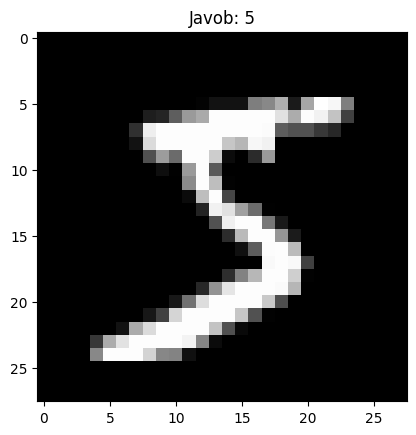

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(x_train.shape)   # (60000, 28, 28)
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Javob: {y_train[0]}")
plt.show()

In [3]:
x_train = x_train / 255.0          # 0–255 ni 0–1 ga keltiramiz
x_test  = x_test / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)   # CNN "1 kanal" (oq-qora) kutadi
x_test  = x_test.reshape(-1, 28, 28, 1)

In [4]:
model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")   # 10 ta raqam = 10 ta chiqish
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.fit(x_train, y_train, epochs=5, validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 46s 26ms/step - accuracy: 0.9538 - loss: 0.1501 - val_accuracy: 0.9835 - val_loss: 0.0533
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.9848 - loss: 0.0500 - val_accuracy: 0.9895 - val_loss: 0.0366
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 83s 25ms/step - accuracy: 0.9888 - loss: 0.0346 - val_accuracy: 0.9910 - val_loss: 0.0322
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 81s 25ms/step - accuracy: 0.9915 - loss: 0.0263 - val_accuracy: 0.9893 - val_loss: 0.0355
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.9935 - loss: 0.0198 - val_accuracy: 0.9913 - val_loss: 0.0356


In [12]:
loss, acc = model.evaluate(x_test, y_test)
print("Accuracy:", acc)       # taxminan 0.99 chiqishi kerak

model.save("digit_cnn.keras")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9909 - loss: 0.0303
Accuracy: 0.9908999800682068


In [13]:
from PIL import Image, ImageOps

img = Image.open("/content/Screenshot 2026-10-23 224432.png").convert("L")  # oq-qora
img = img.resize((28, 28))
img = ImageOps.invert(img)

arr = np.array(img) / 255.0
arr = arr.reshape(1, 28, 28, 1)

pred = model.predict(arr)
print("It may this nummber:", np.argmax(pred))
print("Trust:", np.max(pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
It may this nummber: 2
Trust: 0.97446764


In [14]:
import io, base64
from IPython.display import display, HTML, JSON
from google.colab import output
from PIL import Image

def predict_digit(data_url):
    b64 = data_url.split(",")[1]
    img = Image.open(io.BytesIO(base64.b64decode(b64))).convert("L")
    img = img.resize((28, 28))
    arr = np.array(img) / 255.0
    arr = arr.reshape(1, 28, 28, 1)
    pred = model.predict(arr, verbose=0)[0]
    return JSON({"digit": int(np.argmax(pred)), "conf": float(np.max(pred))})

output.register_callback("predict_digit", predict_digit)

In [16]:
display(HTML("""
<canvas id="c" width="280" height="280"
  style="border:2px solid #888; background:black; cursor:crosshair"></canvas>
<br>
<button onclick="predictIt()">Tanish</button>
<button onclick="clearIt()">Tozalash</button>
<h2 id="out">Raqam chizing...</h2>

<script>
const c = document.getElementById('c');
const ctx = c.getContext('2d');
ctx.fillStyle = 'black';
ctx.fillRect(0, 0, 280, 280);
ctx.strokeStyle = 'white';
ctx.lineWidth = 20;
ctx.lineCap = 'round';

let drawing = false;
c.onmousedown = e => { drawing = true; ctx.beginPath(); ctx.moveTo(e.offsetX, e.offsetY); };
c.onmousemove = e => { if (drawing) { ctx.lineTo(e.offsetX, e.offsetY); ctx.stroke(); } };
c.onmouseup = () => drawing = false;
c.onmouseleave = () => drawing = false;

function clearIt() {
  ctx.fillStyle = 'black';
  ctx.fillRect(0, 0, 280, 280);
  document.getElementById('out').innerText = 'Paint the photo...';
}

async function predictIt() {
  const r = await google.colab.kernel.invokeFunction(
    'predict_digit', [c.toDataURL('image/png')], {});
  const d = r.data['application/json'];
  document.getElementById('out').innerText =
    'It may be: ' + d.digit + '  (' + (d.conf * 100).toFixed(1) + '%)';
}
</script>
"""))